In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md
import os

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

def calc_ccc(x, y):
    x = np.asarray(x)
    y = np.asarray(y)

    mx = np.mean(x)
    my = np.mean(y)
    vx = np.var(x, ddof=0)
    vy = np.var(y, ddof=0)
    sxy = np.cov(x, y, ddof=0)[0, 1]

    return 2 * sxy / (vx + vy + (mx - my) ** 2)

def RMSE(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))

def load_pf_data(protein, model_name, ensemble_dir="MD_DATA", exp_dir="EXP_DATA/PF_Nguyen_2018"):
    exp = pd.read_csv(f"../../{exp_dir}/{protein}.csv")
    residues = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/exp_residues.txt")
    priorPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/prior_lnPF.txt"))

    # stats is currently unused, so this read is commented out.
    # stats = pd.read_csv(f"../../{ensemble_dir}/{protein}/{model_name}/stats_df.csv")
    stats = None

    if model_name in ("rewBV2006", "rewBV2006ang"):
        rewdata = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/reweighting_chi2_phi_theta.txt")
        chi2, phi, thetas = rewdata[0, :], rewdata[1, :], rewdata[2, :]
        rewPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/rew_lnPF.txt"))
    else:
        rewdata = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_reweighting_chi2_phi_theta.txt")
        chi2, phi, thetas = rewdata[0, :], rewdata[1, :], rewdata[2, :]
        rewPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_rew_lnPF.txt"))

    idxs = [list(exp["Model_residue"]).index(ele) for ele in residues]

    return exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs


# --- Utility functions ---
def RMSE(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))

def find_xtc_filenames(path_to_dir, suffix=".xtc"):
    filenames = os.listdir(path_to_dir)
    return [filename for filename in filenames if filename.endswith(suffix)]

def compute_free_energy(protein, model_name, native_contacts_dir, ensemble_dir="MD_DATA", nbins=30, unfolded_cutoff=0.1, wopt=None):
    k = 0.008314
    T = 298.0
    kT = k * T

    ntrajs = len(find_xtc_filenames(f"../../{ensemble_dir}/{protein}/"))
    # get correct traj order
    trajs = np.array(sorted(list(np.arange(ntrajs).astype(str)))).astype(int)

    # Load Q data
    for i in trajs:
        if 'M' in model_name:
            frames = np.loadtxt(f"../../{ensemble_dir}/{protein}/rewM10/okframes_traj{i}.txt").astype(int)
            Q = np.loadtxt(f"../../{ensemble_dir}/{protein}/{native_contacts_dir}/Q{i}.txt")[frames]
            if i == 0:
                Q_all = Q
            else:
                Q_all = np.concatenate((Q_all, Q))
        else: # for models where no filtering was needed
            Q = np.loadtxt(f"../../{ensemble_dir}/{protein}/{native_contacts_dir}/Q{i}.txt")
            if i == 0:
                Q_all = Q
            else:
                Q_all = np.concatenate((Q_all, Q))
    if wopt is None:
        try:
            wopt = np.load(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_wopt.npy")
        except:
            wopt = np.load(f"../../{ensemble_dir}/{protein}/{model_name}/wopt.npy")
        wopt = wopt / np.sum(wopt)

    # Histograms
    def compute_FEL(Q, weights=None):
        counts, bins = np.histogram(Q, bins=nbins, weights=weights)
        centers = 0.5 * (bins[1:] + bins[:-1])
        p = counts / np.sum(counts)
        p[p <= 0] = np.nan
        fel = -np.log(p) * kT
        fel -= np.nanmin(fel)
        return centers, fel * 0.239005736

    centers_prior, fel_prior = compute_FEL(Q_all)
    centers_post, fel_post = compute_FEL(Q_all, weights=wopt)

    # Energetics 1: completely unfolded state relative to native state (comparable to what HDX probes)
    unfolded = np.where(Q_all < unfolded_cutoff)[0]
    # get cutoff for folded state from FEL
    min_Q_idx = np.where(fel_prior ==np.min(fel_prior))[0]
    minQ = centers_prior[min_Q_idx]
    native_cutoff = 0.7 * minQ
    folded = np.where(Q_all > native_cutoff)[0]

    dG_prior = -kT * np.log(len(folded) / len(unfolded)) * 0.239005736
    dG_post = -kT * np.log(np.sum(wopt[folded]) / np.sum(wopt[unfolded])) * 0.239005736

    # Energetics 2: native state relative to the rest (including potential intermediates, comparable to what cDNA proteolysis probes)
    # criteria: the main energy barrier between native and unfolded must be overcome --> cutoff decided as the max free energy between Q 0.2 and 0.8
    mask = (centers_prior > 0.2) & (centers_prior < 0.8)
    max_Q_idx = np.where(fel_prior ==np.max(fel_prior[mask]))[0][0]
    native_cutoff2 = centers_prior[max_Q_idx]
    folded = np.where(Q_all > native_cutoff2)[0]
    unfolded = np.where(Q_all < native_cutoff2)[0]

    dG_prior2 = -kT * np.log(len(folded) / len(unfolded)) * 0.239005736
    dG_post2 = -kT * np.log(np.sum(wopt[folded]) / np.sum(wopt[unfolded])) * 0.239005736

    return centers_prior, fel_prior, centers_post, fel_post, dG_prior, dG_post, dG_prior2, dG_post2, native_cutoff, native_cutoff2

outpath = './ACP_plots/'


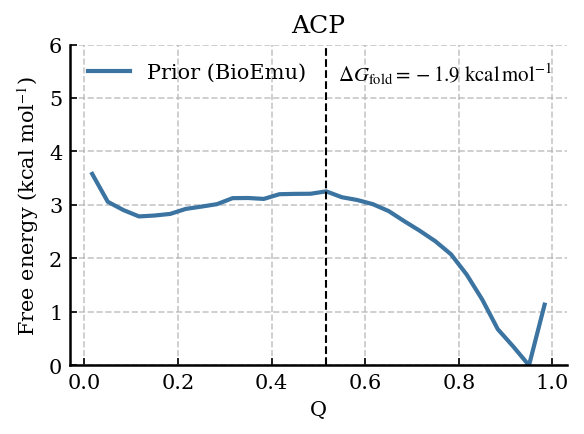

In [14]:
model_name = 'rewM10'
protein = 'ACP'
unfolded_cutoff = 0.1
native_contacts_dir = 'native_contacts'
COLOR = "#3B73A1"

centers_prior, fel_prior, centers_post, fel_post, dG_prior, dG_post, dG_prior2, dG_post2, native_cutoff, native_cutoff2 = compute_free_energy(protein, model_name=model_name, ensemble_dir='BIOEMU_DATA', native_contacts_dir=native_contacts_dir, unfolded_cutoff=unfolded_cutoff)

fig, ax = plt.subplots(figsize=(4, 3))

ax.plot(centers_prior, fel_prior, color=COLOR, linewidth=2, label='Prior (BioEmu)')
ax.axvline(native_cutoff2, color="k", linestyle="--", linewidth=1)

ax.text(0.97, 0.95, rf"$\Delta G_{{\mathrm{{fold}}}} = {dG_prior2:.1f}\ \mathrm{{kcal\,mol^{{-1}}}}$", transform=ax.transAxes, ha="right", va="top")

ax.set_xlabel("Q")
ax.set_ylabel("Free energy (kcal mol$^{-1}$)")
ax.set_title("ACP")
ax.set_ylim(0,6)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="both", which="both", top=False, right=False)

ax.legend(loc='best')

plt.tight_layout()
plt.savefig(outpath+f"ACP_prior_FEL.pdf", dpi=300, bbox_inches="tight")
plt.show()

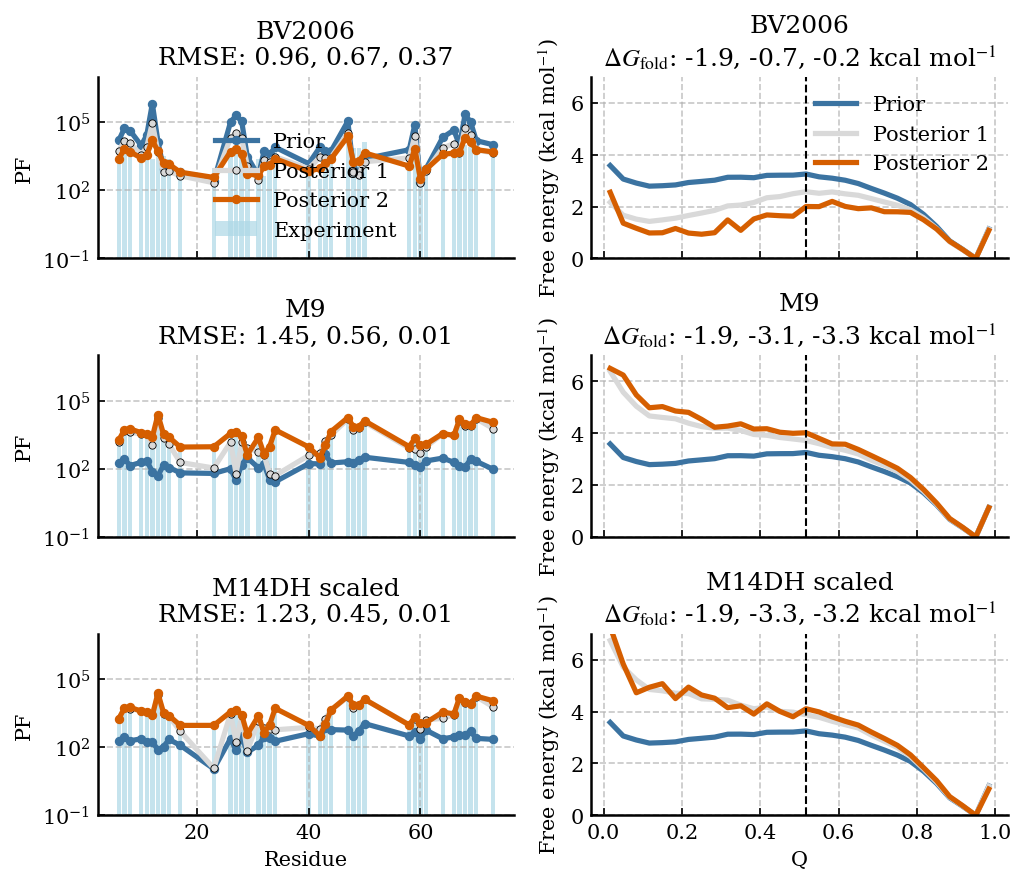

In [25]:
# --------------------------------------------------
# Models and protein
# --------------------------------------------------
protein = "ACP"
models = ["rewBV2006", "rewM9", "rewM14DH_scaled"]
model_labels = ["BV2006", "M9", "M14DH scaled"]
native_contacts_dir = "native_contacts"
unfolded_cutoff = 0.1

# --------------------------------------------------
# Colours
# --------------------------------------------------
COLOR3 = "#3B73A1"  # prior
COLOR2 = "#D9D9D9"  # posterior 1: elbow
COLOR1 = "#D55E00"  # posterior 2
EXP_COLOR = "lightblue"

# --------------------------------------------------
# Create 3 × 2 figure
# --------------------------------------------------
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(7, 6), sharex="col")

for i, (model, model_label) in enumerate(zip(models, model_labels)):
    model_dir = f"../../BIOEMU_DATA/{protein}/{model}/"

    # --------------------------------------------------
    # Load prior, elbow and final weights
    # --------------------------------------------------
    if "BV" in model:
        wopt_elbow = np.load(f"{model_dir}/wopt_elbow.npy")
        wopt = np.load(f"{model_dir}/wopt.npy")
    else:
        wopt_elbow = np.load(f"{model_dir}/log_lambda_wopt_elbow.npy")
        wopt = np.load(f"{model_dir}/log_lambda_wopt.npy")

    prior_weights = np.ones(len(wopt)) / len(wopt)

    # --------------------------------------------------
    # Load experimental PFs
    # --------------------------------------------------
    exp, residues, priorPF_loaded, posterior2PF_loaded, chi2, phi, thetas, stats, idxs = load_pf_data(protein, model_name=model, ensemble_dir="BIOEMU_DATA", exp_dir="EXP_DATA/PF_Nguyen_2018")
    expPF = np.asarray(exp["PF"][idxs])
    residues = np.asarray(residues)

    # --------------------------------------------------
    # Calculate prior, posterior 1 and posterior 2 PFs
    # --------------------------------------------------
    if "BV" in model:
        priorPF = np.exp(np.loadtxt(f"../../BIOEMU_DATA/{protein}/{model}/prior_lnPF.txt"))
        posterior2PF = np.exp(np.loadtxt(f"../../BIOEMU_DATA/{protein}/{model}/rew_lnPF.txt"))
        posterior1PF = np.exp(np.loadtxt(f"../../BIOEMU_DATA/{protein}/{model}/rew_lnPF_elbow.txt"))
    else:
        priorPF = np.exp(np.loadtxt(f"../../BIOEMU_DATA/{protein}/{model}/prior_lnPF.txt"))
        posterior2PF = np.exp(np.loadtxt(f"../../BIOEMU_DATA/{protein}/{model}/log_lambda_rew_lnPF.txt"))
        posterior1PF = np.exp(np.loadtxt(f"../../BIOEMU_DATA/{protein}/{model}/log_lambda_rew_lnPF_elbow.txt"))

    pf_rmse_prior = RMSE(np.log10(expPF), np.log10(priorPF))
    pf_rmse_posterior1 = RMSE(np.log10(expPF), np.log10(posterior1PF))
    pf_rmse_posterior2 = RMSE(np.log10(expPF), np.log10(posterior2PF))

    # --------------------------------------------------
    # Plot protection factors
    # --------------------------------------------------
    ax = axes[i, 0]
    ax.bar(residues, expPF, width=0.8, color=EXP_COLOR, alpha=0.7, label="Experiment")
    ax.plot(residues, priorPF, color=COLOR3, linewidth=2.5, marker="o", markersize=3.5, label="Prior")
    ax.plot(residues, posterior1PF, color=COLOR2, linewidth=2.5, marker="o", markersize=3.5, markeredgecolor="black", markeredgewidth=0.4, label="Posterior 1")
    ax.plot(residues, posterior2PF, color=COLOR1, linewidth=2.5, marker="o", markersize=3.5, label="Posterior 2")
    ax.set_title(f"{model_label}\nRMSE: {pf_rmse_prior:.2f}, {pf_rmse_posterior1:.2f}, {pf_rmse_posterior2:.2f}")
    ax.set_yscale("log")
    ax.set_ylabel("PF")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="both", which="both", top=False, right=False)
    ax.yaxis.set_ticks_position("left")
    ax.set_ylim(1e-1,1e7)

    # --------------------------------------------------
    # Calculate prior and posterior 2 FELs using the
    # existing compute_free_energy function
    # --------------------------------------------------
    centers_prior, fel_prior, centers_posterior2, fel_posterior2, dG_prior, dG_posterior2, dG_prior2, dG_posterior2_fold, native_cutoff, native_cutoff2 = compute_free_energy(
        protein, model_name=model, ensemble_dir="BIOEMU_DATA",
        native_contacts_dir=native_contacts_dir, unfolded_cutoff=unfolded_cutoff, wopt=wopt,
    )

    # --------------------------------------------------
    # Calculate posterior 1 FEL using the same function
    # --------------------------------------------------
    centers_prior, fel_prior, centers_posterior1, fel_posterior1, dG_prior, dG_posterior1, dG_prior2, dG_posterior1_fold, native_cutoff, native_cutoff2  = compute_free_energy(
        protein, model_name=model, ensemble_dir="BIOEMU_DATA",
        native_contacts_dir=native_contacts_dir, unfolded_cutoff=unfolded_cutoff, wopt=wopt_elbow,
    )

    # --------------------------------------------------
    # Plot free-energy landscapes
    # --------------------------------------------------
    ax = axes[i, 1]
    ax.plot(centers_prior, fel_prior, color=COLOR3, linewidth=2.5, label="Prior")
    ax.plot(centers_posterior1, fel_posterior1, color=COLOR2, linewidth=2.5, label="Posterior 1")
    ax.plot(centers_posterior2, fel_posterior2, color=COLOR1, linewidth=2.5, label="Posterior 2")
    ax.axvline(native_cutoff2, color="black", linestyle="--", linewidth=1)
    ax.set_title(rf"{model_label}" + "\n" + rf"$\Delta G_{{\mathrm{{fold}}}}$: {dG_prior2:.1f}, {dG_posterior1_fold:.1f}, {dG_posterior2_fold:.1f} kcal mol$^{{-1}}$")
    ax.set_ylabel("Free energy (kcal mol$^{-1}$)")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="both", which="both", top=False, right=False)
    ax.yaxis.set_ticks_position("left")
    ax.set_ylim(0,7)

axes[-1, 0].set_xlabel("Residue")
axes[-1, 1].set_xlabel("Q")
axes[0, 0].legend(loc="best", frameon=False)
axes[0, 1].legend(loc="best", frameon=False)

plt.tight_layout()
plt.savefig(outpath + f"{protein}_PF_FEL_BV2006_M9_M14DH_scaled.pdf", dpi=300, bbox_inches="tight")
plt.show()